![logo](images/untumbes.PNG)

<center><b>Prof. Dr. Jorge Zavaleta - zavaleta.jorge@gmail.com</b></center>

# Agrupamientos espectrales

Una de las principales limitaciones del algoritmo de agrupamiento de k-means es su tendencia a buscar clusters de forma globular. Por lo tanto, no funciona cuando se aplica a datasets con grupos de formas arbitrarias o cuando los centroides del grupo se superponen entre sí. 

La agrupación espectral puede superar esta limitación explotando las propiedades del gráfico de similitud para superar dichas limitaciones. 

In [1]:
# librarys
# libray
import pandas as pd
import numpy as np
from sklearn import cluster
import matplotlib.pyplot as plt
%matplotlib inline
#
import warnings
warnings.filterwarnings("ignore")

In [2]:
# datos bi-dimensionales
data1 = pd.read_csv('data/2d_data.txt', delimiter=' ', names=['x','y'])
data2 = pd.read_csv('data/elliptical.txt', delimiter=' ', names=['x','y'])

In [3]:
# visualizar los datos
data1.head()

,x,y
0,0.0433,0.6300
1,0.0467,0.7033
2,0.0500,0.6833
3,0.0500,0.6900
4,0.0500,0.6933


In [4]:
# visulizar los datos
data2.head()

,x,y
0,0.0043,0.1927
1,-0.1463,-0.0819
2,-0.0179,-0.0826
3,0.0891,0.2139
4,-0.0302,0.1504


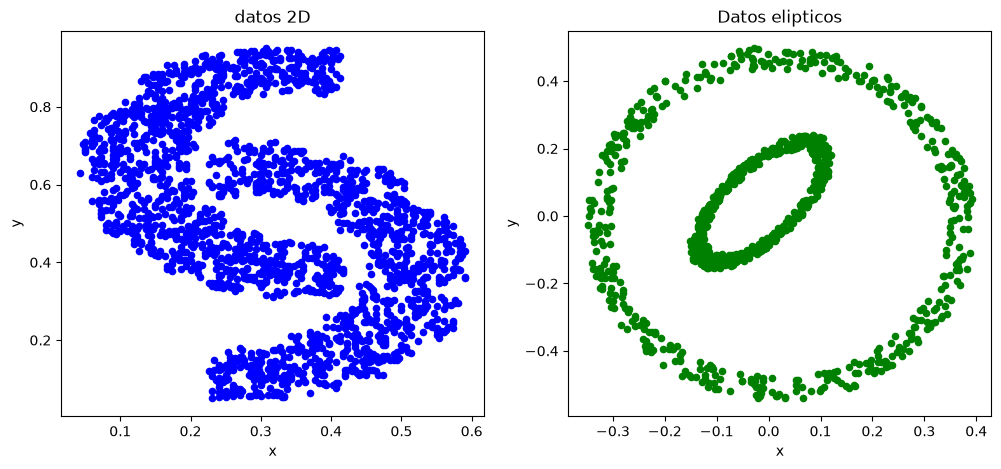

In [5]:
# Visualización gráfica de los datos
fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,5))
data1.plot.scatter(x='x',y='y',ax=ax1, color='blue')
ax1.set_title('datos 2D');
data2.plot.scatter(x='x',y='y',ax=ax2, color='green')
ax2.set_title('Datos elipticos');

>## Aplicacion de k-means a los datasets (con k=2)

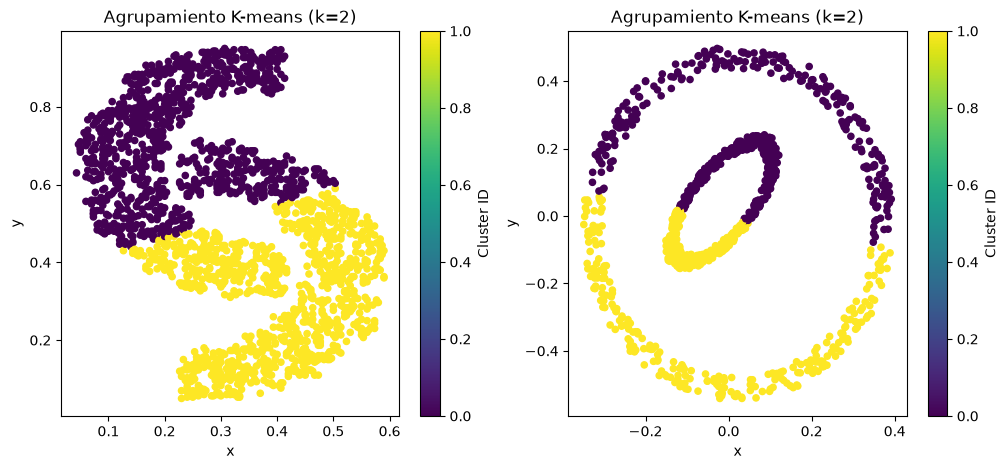

In [6]:
# Aplicacion de k-means a los datasets (con k=2)
#dataset 1
k_means = cluster.KMeans(n_clusters=2, max_iter=50, random_state=1)
k_means.fit(data1)
labels1 = pd.DataFrame(k_means.labels_,columns=['Cluster ID'])
result1 = pd.concat((data1,labels1), axis=1)
#
#dataset 2
k_means2 = cluster.KMeans(n_clusters=2, max_iter=50, random_state=1)
k_means2.fit(data2)
labels2 = pd.DataFrame(k_means2.labels_,columns=['Cluster ID'])
result2 = pd.concat((data2,labels2), axis=1)
#
# grafico dataset1
fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,5))
result1.plot.scatter(x='x',y='y',c='Cluster ID',colormap='viridis',ax=ax1)
ax1.set_title('Agrupamiento K-means (k=2)');
#
# grafico dataset 2
result2.plot.scatter(x='x',y='y',c='Cluster ID',colormap='viridis',ax=ax2)
ax2.set_title('Agrupamiento K-means (k=2)');

Los gráficos muestran el bajo rendimiento de la agrupación de k-means. A continuación, aplicamos agrupamiento espectral a datasets.

La **agrupación espectral** convierte los datos en un gráfico de similitud y aplica el algoritmo de partición del gráfico de corte normalizado para generar los grupos.

En el siguiente ejemplo, se usa la función de base radial gaussiana como nuestra medida de afinidad (similitud).

Los usuarios deben **ajustar** el valor del parámetro del kernel (gamma) para obtener los grupos apropiados para el conjunto de datos determinado.

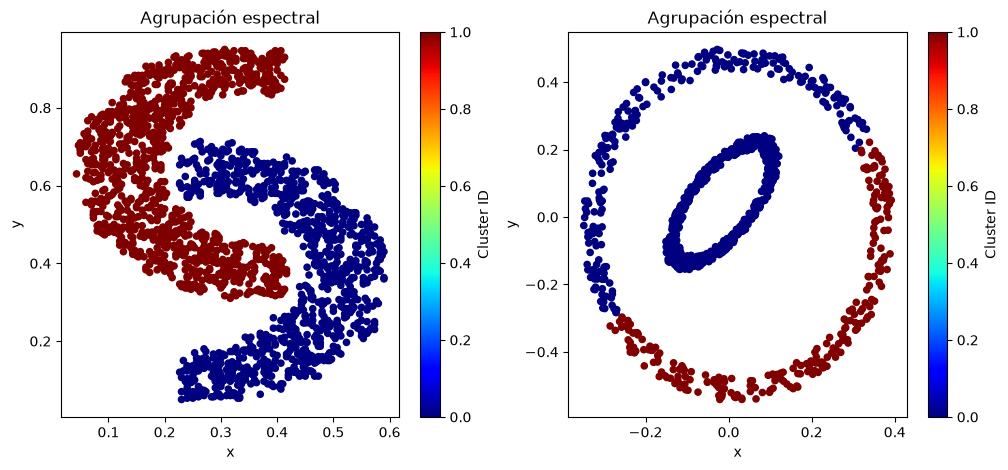

In [7]:
# spectral clustering para data 1
# data 1, gamma = 5000
spectral = cluster.SpectralClustering(n_clusters=2,random_state=1,affinity='rbf',gamma=5000)
spectral.fit(data1)
labels1 = pd.DataFrame(spectral.labels_,columns=['Cluster ID'])
result1 = pd.concat((data1,labels1), axis=1)

# data 2, gamma = 100
spectral2 = cluster.SpectralClustering(n_clusters=2,random_state=1,affinity='rbf',gamma=100)
spectral2.fit(data2)
labels2 = pd.DataFrame(spectral2.labels_,columns=['Cluster ID'])
result2 = pd.concat((data2,labels2), axis=1)

# graficos data 1
fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,5))
result1.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax1)
ax1.set_title('Agrupación espectral');

# graficos data 2
result2.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax2)
ax2.set_title('Agrupación espectral');

Los gráficos anteriores muestran el bajo rendimiento de la agrupación de k-means. 
Aplicación del agrupamiento espectral a los datasets.
La agrupación espectral convierte los datos en un gráfico de similitud y aplica el algoritmo de partición del gráfico de corte normalizado para generar los grupos. 

En el ejemplo se usa la función de base radial gaussiana como nuestra medida de afinidad (similitud). 

Los usuarios deben ajustar el valor del parámetro del kernel (**gamma**) para obtener los grupos apropiados para el dataset determinado.

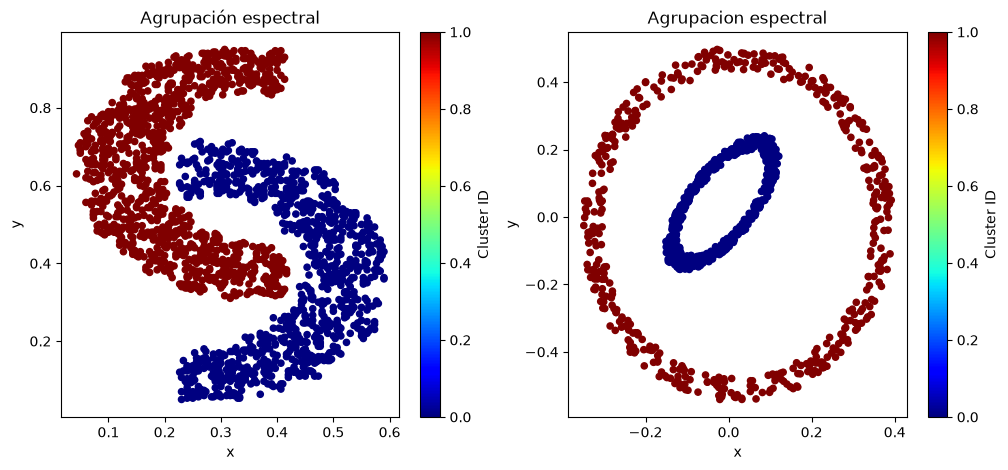

In [8]:
# spectral clustering
# data 1, gamma=5000
spectral = cluster.SpectralClustering(n_clusters=2,random_state=1,affinity='rbf',gamma=5000)
spectral.fit(data1)
labels1 = pd.DataFrame(spectral.labels_,columns=['Cluster ID'])
result1 = pd.concat((data1,labels1), axis=1)
# data2 , gamma = 100
spectral2 = cluster.SpectralClustering(n_clusters=2,random_state=1,affinity='rbf',gamma=200)
spectral2.fit(data2)
labels2 = pd.DataFrame(spectral2.labels_,columns=['Cluster ID'])
result2 = pd.concat((data2,labels2), axis=1)
#
fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,5))
result1.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax1)
ax1.set_title('Agrupación espectral');
#
result2.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax2)
ax2.set_title('Agrupacion espectral');

---
<center><b>&copy;Jorge Zavaleta, Mineria de Datos 2026</b></center>